# 2023年Java大厂面试｜07：ArrayList、LinkedList、HashMap与集合源码

> 学习目标：从复杂度与数据结构解释集合操作，读懂ArrayList扩容、HashMap寻址/put/get/resize，讲清List转换、树化、重复判断和线程安全边界。

**主要依据：** `5.2023版Java面试教程/07-常见集合篇/PPT/07-常见集合篇.pptx`，共100页。已读取课件文字、组合形状、表格与备注，查看8张去重嵌入图片总览，并单独检查集合体系、复杂度表和HashMap桶结构图。第100页为空白。本笔记内嵌3张原课件图，图中存在简化表述时在正文说明。

**配套阅读：** 网盘`资料/hashmap源码.md`的预览正文，包含put、resize和get三段源码及中文注释。已分段阅读[飞书《常见集合篇》](https://heuqqdmbyk.feishu.cn/wiki/Pbm0w1CgFi1Px4klDNdcP57inJc)的复杂度、List、树/散列、HashMap问答、HashSet/Hashtable和面试模拟主要正文，单独查看Hashtable比较表。网页标示2024年12月30日修改。飞书部分源码以图片出现，未逐张核验全部网页图片，相关机制以实际读到的PPT文字及配套MD源码补足，未采用评论区内容。

视频目录17节已核对全部标题，**未观看或转写**。资料中另有`hash-demo.jar`，课件标示需JDK14以上运行，**未下载或运行此程序**。MD网页预览可读，下载尝试未取得本地文件，未将网页预览说成已运行工程。

课件明确以**JDK 1.8**源码为主要分析对象，具体更新版本与片段可能有差异。“课件要点”说明原问题和流程，“修正”“补充”说明边界及工程用法。较新API会标注引入版本，补充内容未逐项联网核验最新JDK实现。

Java代码是学习片段，**未编译或执行**，未运行课件JAR、并发压测或性能测试。时间复杂度推导属于理论分析，不代表实测耗时。讲义里的“我阅读过”“我们项目”是课程口述，不能直接写成个人经历。

### 阅读路线

- 1～4：集合体系、时间/空间复杂度与均摊分析
- 5～10：数组、ArrayList构造、扩容、操作、遍历与容量规划
- 11～15：数组/List转换、浅拷贝、链表和List选择
- 16～18：线程安全、二叉搜索树和红黑树
- 19～27：散列、HashMap寻址、put/get、扩容、树化和key契约
- 28～31：JDK7并发迁移、HashSet、Hashtable及有序/并发Map补充
- 32～36：源码阅读、面试自测、练习、选型与来源勘误


## 1. 集合体系：Collection与Map

**课件第2～3页、在线讲义导学：** List、Set、Map是本篇主要入口，常见实现包括ArrayList、LinkedList、HashMap、HashSet、TreeMap与ConcurrentHashMap。

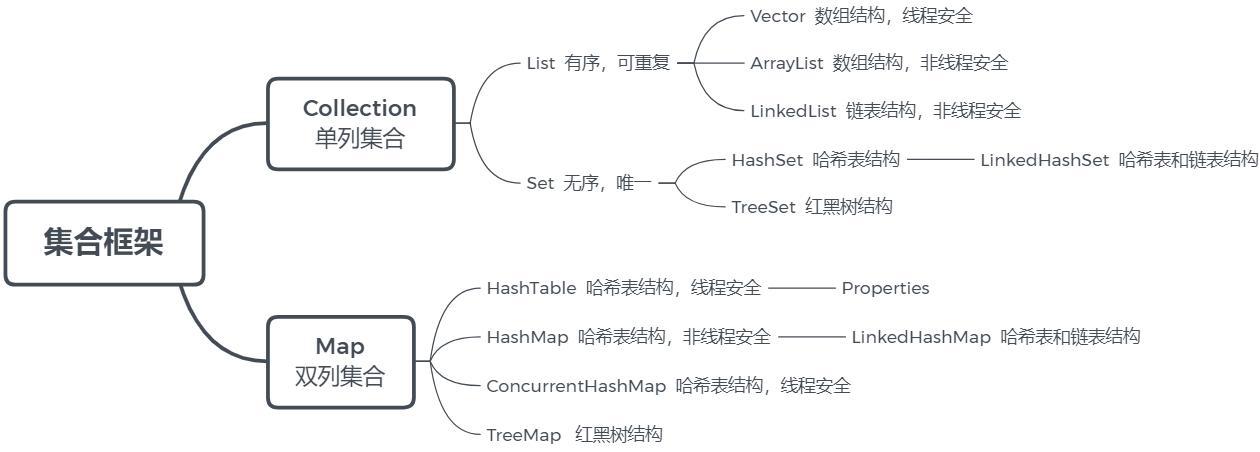

| 接口/类型 | 数据语义 | 常见实现与特点 |
|---|---|---|
| Collection | 一组元素的公共接口 | List、Set、Queue等子接口 |
| List | 按位置形成序列，可重复 | ArrayList动态数组，LinkedList双向链表 |
| Set | 按相应相等规则保持唯一 | HashSet、LinkedHashSet、TreeSet |
| Queue/Deque | 排队或两端操作 | ArrayDeque、LinkedList等，图中未展开 |
| Map | key到value的映射 | HashMap、LinkedHashMap、TreeMap、Hashtable、ConcurrentHashMap |

**补充图的范围：** Map不继承Collection。Queue/Deque也是集合体系的一部分，不能因为课件只画List/Set就断言Collection只有这两个子接口。HashMap等结构在此主要按JDK8讨论。

“有序”需要区分含义：List具有位置顺序，通常体现插入形成的序列，并不自动按大小排序。LinkedHashSet/LinkedHashMap可维护迭代次序，TreeSet/TreeMap按自然顺序或Comparator排序。HashSet/HashMap不承诺迭代顺序，也不意味着每次迭代都随机变化。

HashMap的key唯一，value可以重复。HashSet的元素唯一性依赖正确的equals/hashCode。TreeSet/TreeMap依据比较结果判断相同位置，通常应让比较器与equals保持一致。

**面试表达：** 先说接口语义，再说实现结构与适合的操作。将“集合框架”与某一个实现的默认容量、线程安全或null规则分开，避免把HashMap特征套在所有Map上。


## 2. 时间复杂度：数据规模增长时做多少工作

**课件第5～7、13、15页：** 时间复杂度描述执行时间与数据规模n的增长关系。大O忽略不改变增长阶的常量、系数和低阶项。

例如循环累加n个数，按某种计数模型可得`T(n)=3n+3`，写为O(n)。课程“每行1ms”只是教学假设，不能拿公式计算真实Java代码耗时。CPU、缓存、JIT、IO和输入分布都会影响常数。

| 量级 | 常见操作示例 | 前提 |
|---|---|---|
| O(1) | 数组按下标访问 | 不包含额外线性查找 |
| O(log n) | 有序数组二分查找 | 已排序、随机访问便捷 |
| O(n) | 线性查找 | 单条比较成本按常数估算 |
| O(n log n) | 常见高效比较排序 | 具体算法与情况需说明 |
| O(n²) | 两层均遍历n次的循环 | 内部不再包含额外高成本操作 |
| O(n³)、O(n^k) | 多层规模相关循环 | k为固定常数 |
| O(2^n)、O(n!) | 某些穷举搜索 | 输入较大时通常难以直接扩展 |

**补充数学含义：** Big-O描述渐近上界，面试通常用它表达主要增长阶。严格需要上下界时可进一步讨论Θ、Ω。不能因某操作属于O(n)就断言在所有输入和设备上一定比另一个O(n log n)实现快。

分析顺序：明确n是什么，确定关键操作执行次数，分别分析分支/循环/方法调用，再说明最好、平均、最坏或均摊情况。两个独立规模n、m不应直接混成n，比如嵌套遍历两个列表通常是O(nm)。

**集合上的提醒：** 一行`list.get(i)`在ArrayList与LinkedList上成本不同。复杂度要分析调用的真实操作，而不只是代码行数。hashCode/equals若遍历长字符串或复杂对象，也可能增加操作成本。


## 3. 常数、线性、平方与对数循环

**课件第8～12页：** 固定100次循环是O(1)，遍历n次是O(n)，双层n次是O(n²)，每次倍增直到n是O(log n)。

~~~java
// 相对输入n而言，固定100次，O(1)。
for (int i = 0; i < 100; i++) consume(i);

// O(n)。
for (int i = 0; i < n; i++) consume(i);

// O(n²)。
for (int i = 0; i < n; i++) {
    for (int j = 0; j < n; j++) consume(i, j);
}

// 对int范围的n，用long保存倍增变量避免课程int示例的溢出。
for (long i = 1; i <= n; i *= 2) consume(i);
~~~

这些片段假定consume是常数成本，且n为合理的非负int。倍增执行k次后`i=2^k`，退出时k与log₂n同阶。每次乘10对应log₁₀n，两种对数之间只有常数倍，均记O(log n)。

若外层遍历n次，每次执行一次独立对数循环，总计O(n log n)。若是先遍历n次、再执行对数循环，则总计O(n+log n)=O(n)，不能仅因出现两种循环就相乘。

**补充三角循环：** 内层从0走到i，总次数约`n(n-1)/2`，仍是O(n²)。外层和内层的变量关系要实际展开，不能只数循环层数。

**课程示例勘误：** `int i *= 2`或`i *= 10`在较大n时可能溢出，导致实际程序退出条件失效。复杂度证明假定数值操作满足模型，Java实现还需处理整数范围。累加和示例用int也可能溢出，若需真实结果应使用合适类型和边界检查。

**面试回答：** 说清执行次数的推导，固定循环次数与n无关，对数循环每次按固定比例改变规模。给出量级后再说明数值、比较和内部调用的成本前提。
\n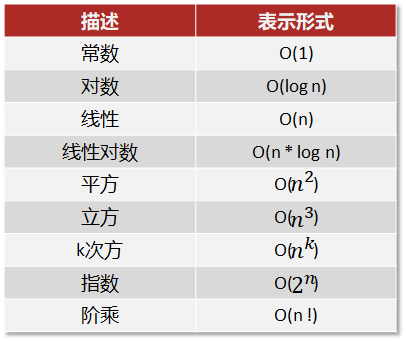\n

## 4. 空间复杂度与均摊复杂度

**课件第14～15页：** 空间复杂度描述额外存储随规模的增长。少量局部变量为O(1)，额外长度n的数组为O(n)。

~~~java
// 假定输入已存在，额外只有固定数量局部变量，O(1)。
long sum = 0;
for (int value : values) sum += value;

// 额外建立长度n的数组，O(n)。
int[] result = new int[n];
for (int i = 0; i < n; i++) result[i] = i;
~~~

**补充统计口径：** 通常统计辅助空间，不把已有输入计入，但输出空间是否包含要明确。递归栈也属于空间。平衡树递归深度可能O(log n)，退化链式树递归深度可能O(n)，因此课件“对数阶空间几乎用不到”不能当成普遍结论。

对象占用字节数与空间复杂度是不同问题。一个数组长度n与n个链表节点都可能O(n)，但节点头、引用、对齐和数组预留空位影响真实内存。不能仅用Big-O判断谁一定占用多少字节。

**均摊复杂度补充：** ArrayList多数末尾add只写一个槽位，有时扩容需复制旧元素。一次扩容是O(n)，但几何增长使一系列追加的总复制工作为线性量级，因此末尾add通常为均摊O(1)。

| 说法 | 含义 |
|---|---|
| 单次最坏O(n) | 恰好触发扩容时复制大量元素 |
| 均摊O(1) | 长期一系列操作平均分配扩容成本 |
| 平均O(1) | 在某种输入/散列分布假设下的期望成本 |

均摊分析不等于“随机平均情况”。也不保证每条请求低延迟。如果某次扩容落在关键请求上，它仍可能产生明显延迟，因此已知规模时可预分配。


## 5. 数组：随机访问与保持逻辑顺序

**课件第18～25页：** 数组提供连续槽位，按索引寻址，未知索引时线性查找，排序后可二分查找。中间插入/删除通常移动后续元素。

课程示意公式是：`元素槽位地址 = 元素区首地址 + i × 槽位宽度`。这表达数组随机访问的原理，不能直接把`array[i]`的值解释成地址。实际Java数组还涉及对象头、长度、边界检查与VM布局。

**补充对象数组：** `Object[]`连续保存的是引用槽位，引用指向的对象可分散在堆上。ArrayList的底层数组也主要保存元素引用，不能说其中所有业务对象本身紧密连续。

| 操作 | 常见复杂度 | 条件 |
|---|---|---|
| 按合法索引读取/替换 | O(1) | 使用随机访问 |
| 未排序数组按值寻找 | O(n) | 最坏需遍历 |
| 有序数组二分寻找 | O(log n) | 已排序，比较成本固定 |
| 有余量末尾追加 | O(1) | 无需移动/扩容 |
| 中间插入/删除并保持序列 | O(n) | 后续元素需要位移 |

**修正“保持连续性”：** 数组在物理上已经连续，删除后移动元素主要是为维持有效元素的逻辑连续区与原有顺序。若业务允许无序，可用末尾元素覆盖删除位置降低某些操作成本，但会改变顺序，不能直接套在List语义上。

**零下标补充：** 从0开始可以自然表达元素偏移，半开区间`[0,n)`也便于长度计算。课件“从1开始多一次减法，所以性能不高”只是解释性简化，不能据此断言所有一基索引语言都慢。编译器优化与语言设计还有其他因素。

Java数组长度固定。要增长通常建立新数组并复制内容，动态数组集合在这个基础上管理size、capacity及扩容。


## 6. ArrayList成员：size与capacity

**课件第27～29页，在线讲义3.2：** 以JDK8为主从成员变量、构造方法和关键方法分析ArrayList。

~~~java
private static final int DEFAULT_CAPACITY = 10;
private static final Object[] EMPTY_ELEMENTDATA = {};
private static final Object[] DEFAULTCAPACITY_EMPTY_ELEMENTDATA = {};
transient Object[] elementData;
private int size;
~~~

| 字段/概念 | 含义 |
|---|---|
| size | 实际有效元素数量，List.size()返回它 |
| capacity | 底层elementData.length，可以大于size |
| EMPTY_ELEMENTDATA | 显式零容量等情况使用的共享空数组 |
| DEFAULTCAPACITY_EMPTY_ELEMENTDATA | 无参构造的空数组标记，用于首次增长规则 |
| modCount | 继承的修改计数，辅助迭代器检查 |

`new ArrayList<>(10)`只预留容量，size仍为0。此时`get(0)`会越界，因为没有有效元素，不能把容量当成已存在10个null元素。

两个空数组长度都为0，但对象标记不同。JDK8通过对象身份判断是否使用无参构造的默认空数组，从而决定首次至少分配10，而显式零容量通常首次按需要分配1。

**补充transient：** 字段不由默认序列化机制直接按普通字段保存，不意味着元素永远不能序列化。ArrayList有相应序列化处理，使用时还受元素是否支持序列化等条件影响。课件“当前对象不参与序列化”应明确指该字段的默认处理范围。

ArrayList支持null和重复元素，按位置访问。它没有对并发写入提供安全保证，modCount/迭代器检查不能代替同步。


## 7. ArrayList构造方法与首次分配

**课件第29、35～36页：** 有无参、指定初始容量和从Collection构造三类常见方式。

~~~java
List<String> a = new ArrayList<>();
List<String> b = new ArrayList<>(10);
List<String> c = new ArrayList<>(0);
List<String> copy = new ArrayList<>(source);
~~~

| 构造方式 | 初始size | JDK8常见分配行为 |
|---|---:|---|
| 无参 | 0 | 先使用默认空数组标记，普通首次add分配10 |
| initialCapacity=10 | 0 | 构造时分配长度10的数组 |
| initialCapacity=0 | 0 | 使用另一空数组标记，普通首次add通常分配1 |
| initialCapacity<0 | 无 | 抛IllegalArgumentException |
| 传入Collection | source.size() | 建立保存元素引用的数组，来源为空则使用空数组 |

**面试原题：** “`ArrayList list = new ArrayList(10)`中的list扩容几次？”仅这条构造语句没有后续add，答案是**没有扩容**。它分配初始数组，这与已有数组增容是不同阶段。

**首次add范围：** “首次分配10”针对无参构造后普通add的常见路径。若无参构造后一次addAll加入大于10个元素，所需容量可能直接按批次需求决定。不能把10解释成所有构造与批量操作的固定初始长度。

从Collection构造通常是浅拷贝：新列表拥有自己的容器存储，但保留元素对象引用。课件中的具体源码片段可能受JDK更新版本影响，可结合实际源码核对是否有类型归一化等分支。

使用泛型避免原题原始类型带来的类型检查缺失，例如`new ArrayList<String>(10)`或菱形语法。预分配只控制容量，不生成业务元素。


## 8. ArrayList的add与约1.5倍扩容

**课件第30～34页：** JDK8的add先保证`size+1`容量，再把元素写到size位置并增加size。

~~~java
// 课程主路径简化，省略边界和其他方法。
public boolean add(E e) {
    ensureCapacityInternal(size + 1);
    elementData[size++] = e;
    return true;
}

private void grow(int minCapacity) {
    int oldCapacity = elementData.length;
    int newCapacity = oldCapacity + (oldCapacity >> 1);
    if (newCapacity < minCapacity) newCapacity = minCapacity;
    // 真正源码还处理MAX_ARRAY_SIZE、溢出及hugeCapacity。
    elementData = Arrays.copyOf(elementData, newCapacity);
}
~~~

`oldCapacity >> 1`对非负容量近似向下取一半，故是约1.5倍，不是永远精确乘1.5。所需minCapacity更大时直接满足需求，超大容量还要处理上限。

对显式初始容量10、逐条追加的常见路径：

| 有效元素增加到 | 底层容量 | 当次是否增容 |
|---|---:|---|
| 1～10 | 10 | 否 |
| 11 | 15 | 10增至15 |
| 16 | 22 | 15增至22 |
| 23 | 33 | 22增至33 |
| 34 | 49 | 33增至49 |

**补充复杂度：** 不扩容的末尾add为O(1)，一次扩容复制数组为O(n)，连续追加均摊O(1)。新旧数组在复制期间同时存在，瞬时内存需求与复制延迟需要考虑。

课件“增加原来容量的1.5倍”容易误读，应说“新容量约为原来的1.5倍”，即增加约0.5倍。复制的是底层引用槽位，通常不会克隆每个业务对象。

新版JDK内部方法名和容量工具可能变化，面试重点是需求检查、几何增长、复制、size写入及边界，而不是将JDK8每个私有方法名当成跨版本不变API。


## 9. ArrayList的读取、插入、删除与遍历

**课件第22～25、30～34页：** ArrayList按索引读取通常为O(1)，中间插入和删除需要移动引用。

~~~java
ArrayList<String> names = new ArrayList<>(4);
names.add("A");
names.add("B");
names.add("C");
String value = names.get(1);
names.add(1, "X");
names.remove(2);
~~~

get(index)先做边界检查，再访问数组槽位。add(index,e)需要校验位置，把index之后的引用向后移动；remove(index)把后续引用向前移动并清空尾槽，避免无意中保留对象引用。

| 场景 | 复杂度 | 说明 |
|---|---:|---|
| get(i) / set(i,x) | O(1) | 随机访问 |
| contains(x) / indexOf(x) | O(n) | 线性比较equals |
| 末尾add | 均摊O(1) | 可能偶发扩容 |
| 指定位置add/remove | O(n) | 位移，可能还要扩容 |
| clear() | O(n) | 逐槽置null以释放引用 |

**LinkedList的对比修正：** LinkedList.get(i)并非“不支持下标查询”，它支持List的索引API，但需要从头或尾遍历到目标位置，复杂度为O(n)。对LinkedList给定节点引用进行插入/删除才是O(1)，通过索引找到节点仍需遍历。

遍历ArrayList通常优先使用增强for或迭代器。遍历中直接结构性修改会触发fail-fast检查的ConcurrentModificationException，但fail-fast只是尽力发现错误，不是并发安全机制。需要删除时使用迭代器的remove，或先收集待删项再批量处理。

**subList边界：** list.subList(from,to)通常返回原列表的视图，结构修改可能相互影响，且父列表结构性修改后视图可能失效。需要独立列表时使用new ArrayList<>(list.subList(...))。


## 10. 预分配与容量规划

**课件第35～36页：** 指定初始容量10的ArrayList只分配容量，不发生扩容。

~~~java
int expected = 1000;
List<Event> events = new ArrayList<>(expected);
for (Event event : source) events.add(event);
~~~

预分配并不保证最终size不超过容量，也不等于把1000个元素放入集合。size仍由实际add次数决定。估算过大则会提前占用内存，估算过小仍需扩容，容量要结合生命周期和峰值使用。

addAll可以一次根据所需长度扩容，通常比逐个触发多次扩容更合适。它仍可能复制现有数组，且传入Collection的迭代、并发修改和元素引用语义需要明确。

clear()清空有效引用但通常保留底层容量，适合复用容器；trimToSize()可把容量缩到size附近，但会复制数组并影响后续追加。长期持有巨大临时容量时才评估收缩，避免频繁抖动。


## 11. 数组与List转换：视图、复制与元素引用

**课件第37～39页、在线讲义3.2.5：** 数组转List常用Arrays.asList，List转数组使用toArray。

~~~java
String[] source = {"aaa", "bbb", "ccc"};
List<String> view = Arrays.asList(source);
source[1] = "ddd";
System.out.println(view.get(1));  // ddd

String[] copy = view.toArray(new String[0]);
source[0] = "changed";
System.out.println(copy[0]);      // aaa
~~~

Arrays.asList返回固定大小的List视图：可以set替换已有位置，但不能add或remove改变长度，否则抛UnsupportedOperationException。数组元素修改会反映到视图，视图的set也会写回数组。

new ArrayList<>(Arrays.asList(source))可得到独立容器，但它仍是元素的浅拷贝。若元素是可变对象，两个容器中的引用指向同一对象。

toArray()无参版本返回Object[]；泛型代码优先使用toArray(new String[0])或JDK11+的toArray(String[]::new)。传入数组容量不足时会新建合适数组，容量过大时多余位置置null。

**包装类型提醒：** Arrays.asList(1,2,3)得到List<Integer>，基本类型数组int[]作为一个整体元素传入时不会自动变成List<Integer>。


## 12. 单向链表：节点与操作成本

**课件第40～44页、在线讲义3.3：** 单向链表节点包含数据和next引用，节点在物理内存中无需连续。

~~~java
static final class Node<E> {
    E item;
    Node<E> next;
    Node(E item, Node<E> next) {
        this.item = item;
        this.next = next;
    }
}
~~~

从头节点沿next查找目标，需要访问路径上的节点。头插只改变少量引用。

| 操作 | 只有头节点引用时的复杂度 |
|---|---:|
| 读取头节点 | O(1) |
| 查找第i个节点 | O(n) |
| 头部插入/删除 | O(1) |
| 已知前驱节点后的插入/删除 | O(1) |
| 按值删除 | O(n) |

“非连续存储”不代表每次访问一定慢到固定倍数，真实成本还受缓存、对象分配和分支影响。复杂度只表达随n增长的趋势。

单向链表无法从当前节点直接回到前驱节点。若删除当前节点但没有前驱引用，通常要从头找，或者在特殊条件下复制后继节点内容，后者不适用于尾节点和身份敏感对象。


## 13. 双向链表与LinkedList

**课件第45～50页：** 双向节点有prev和next，LinkedList维护first、last，支持两端操作。

~~~java
private static class Node<E> {
    E item;
    Node<E> next;
    Node<E> prev;
    Node(Node<E> prev, E item, Node<E> next) {
        this.prev = prev;
        this.item = item;
        this.next = next;
    }
}
~~~

| 操作 | LinkedList常见复杂度 |
|---|---:|
| get(0)、get(size-1) | O(1)附近的端点访问 |
| get(i) | O(min(i,size-i))，总体记O(n) |
| 头尾add/remove | O(1) |
| 给定节点位置插入/删除 | O(1) |
| 按索引插入/删除 | 总体O(n) |

双向链表多两个引用字段，节省了从头找前驱的时间，但每个节点有对象头、数据和引用，内存局部性通常不如连续数组。

Java标准LinkedList同时实现List和Deque，可作为双端队列使用。若只需要队列/栈且不需要链表语义，ArrayDeque常是更直接的选择；具体选型还要考虑null、并发和内存。

**线程安全：** ArrayList与LinkedList都不是线程安全容器。Collections.synchronizedList提供方法级同步，但迭代仍需在外部对包装对象加锁；只读共享可考虑不可变/只读视图。并发队列需求应根据生产者消费者模型选择ConcurrentLinkedQueue等。


## 14. ArrayList与LinkedList如何选择

**课件第48～51页、在线讲义3.3.5：**

| 判断维度 | ArrayList | LinkedList |
|---|---|---|
| 底层 | 动态数组 | 双向链表 |
| 按索引读取 | O(1) | O(n) |
| 线性查找 | O(n) | O(n) |
| 末尾操作 | 均摊O(1) | O(1) |
| 中间按索引插入 | 移动数组，O(n) | 找节点，O(n) |
| 给定节点操作 | 没有公开节点API | 链接调整O(1) |
| 内存局部性 | 连续引用数组较好 | 节点对象和引用开销较大 |
| 线程安全 | 默认不安全 | 默认不安全 |

**修正常见口述：** LinkedList支持List索引API，但按索引查询要遍历。“ArrayList尾部删除一定O(1)”还要考虑清理引用与实现细节，不过常见单次操作可按常数级理解。

选择时先问访问模式。大量按位置读取和遍历通常偏向ArrayList；明确的双端队列操作可用LinkedList或ArrayDeque；频繁中间插入但能够持有稳定节点位置时才可能利用链表优势。若只有索引没有节点引用，链表并不会自动让中间操作变成O(1)。

容量、对象数量、GC、缓存命中、并发访问和API语义都可能比理论阶数更重要。面试回答给出工作负载假设，不要把一个实现绝对化。


## 15. 二叉树、二叉搜索树与退化

**课件第52～60页、在线讲义4.1：** 二叉树每个节点最多有左右两个子节点。BST要求左子树值小于节点、右子树值大于节点，重复值处理要另定规则。

~~~java
static class TreeNode {
    int val;
    TreeNode left;
    TreeNode right;
}
~~~

平衡较好的BST查找、插入和删除通常为O(log n)。如果按有序输入逐个插入，树可能退化成链表，高度为O(n)，操作最坏为O(n)。

“BST查找O(log n)”必须带平衡或平均形态前提。普通BST没有自动平衡保证。删除节点还涉及叶子、单子树和双子树三种情况，替换后必须维持排序性质。

数组存树适合结构规则、索引关系稳定的完全二叉树。链式节点适合稀疏或形状变化的树。堆、BST和红黑树的排序/堆序规则不同，不能只看到“二叉”就互相替代。

重复键如何处理会影响插入、查找和删除。TreeMap的Comparator返回0会把键视作同一映射位置，即使equals不相等，因此比较规则必须稳定。


## 16. 红黑树：用规则控制高度

**课件第61～64页、在线讲义4.1.3：** 红黑树是自平衡BST，节点颜色和路径黑节点规则共同限制高度。

五条常见性质：

1. 每个节点是红色或黑色。
2. 根节点为黑色。
3. 叶子是黑色的空节点。
4. 红节点的子节点必须是黑色。
5. 从任一节点到其叶子后代的路径包含相同数量的黑色节点。

插入和删除后通过重新着色与旋转恢复规则。旋转本身是O(1)的局部操作，但要先从根找到位置，因此查找、插入、删除通常按O(log n)分析。

**HashMap中的树化：** JDK8中链表节点很多时会使用TreeNode红黑树，但树化不是只看链表长度。TREEIFY_THRESHOLD常为8，且桶数组容量未达到MIN_TREEIFY_CAPACITY（常为64）时，resize优先于立即树化。树化/退化阈值与具体JDK实现相关，面试要说明“常见JDK8阈值”，不要当成Map接口契约。

红黑树避免极端碰撞把查找长期退化到线性，但它不解决错误hashCode/equals、并发写入或无限对象增长。树节点比链表节点有更多引用与维护成本。


## 17. 散列表与Hash冲突

**课件第65～76页、在线讲义4.2：** Hash Table通过hash函数把key映射到桶数组位置，冲突可用拉链法解决。

hash(key)需满足相等key得到相同结果；不同key允许碰撞。课件中“不同key必须不同hash”是理想化要求，实际有限整数空间不可能保证。Java的hashCode契约只要求equals相等对象必须有相同hashCode，不要求反向成立。

~~~text
key --hash--> bucket index
同一bucket:
  node1 -> node2 -> node3
~~~

| 操作 | 平均/最坏复杂度 | 条件 |
|---|---|---|
| 计算桶位置 | O(1) | hashCode成本按常数估计 |
| 插入 | 平均O(1)，碰撞链/树影响最坏 | 还要比较equals |
| 查询/删除 | 平均O(1)，链表最坏O(n)，树化约O(log n) | 依赖分布和结构 |

平均O(1)依赖散列分布、负载因子和实现调整，不是每一次都O(1)。字符串hashCode计算本身可能随字符串长度增长；自定义key必须实现稳定的hashCode与equals。

**可变key风险：** key放入HashMap后若参与hash/equals的字段改变，再用新状态查找可能找不到原桶中的节点。不要把可变对象作为Map key，或保证放入期间相关字段不可变。

拉链法节点通常在桶内按链表或树组织。碰撞多时，增加容量、改善hash分布和限制攻击输入都很重要。HashMap红黑树是性能保护措施，不是“冲突不会发生”。


## 18. HashMap整体结构与key相等判断

**课件第77～81页、配套源码put/get：** HashMap底层是数组加桶内链表或红黑树。put先计算桶索引，再处理空桶、相同key、树桶和链表桶。

~~~text
table[index]
  null                 直接新建Node
  首节点key相等       覆盖value
  TreeNode             在红黑树中查找/插入
  普通Node链           遍历，命中覆盖，否则尾部插入
完成后size递增，超过threshold则resize
~~~

判断key是否相同通常同时比较hash和equals：
~~~java
p.hash == hash &&
((k = p.key) == key || (key != null && key.equals(k)))
~~~

先比较hash可以减少equals调用，但hash相等不能证明key相等。相同key覆盖旧value，Map的size不增加；不同key即使hash相同也必须保留为碰撞节点。

HashMap允许一个null key和多个null value，null key的hash按0处理。是否允许null是具体实现规则，不能泛化到Hashtable、ConcurrentHashMap或TreeMap的所有用法。

**不可变key建议：** String、Integer等值类型适合做key，因为hashCode与equals稳定。自定义key用IDE生成或手工保证二者一致，并测试放入、查找、删除和碰撞场景。
\n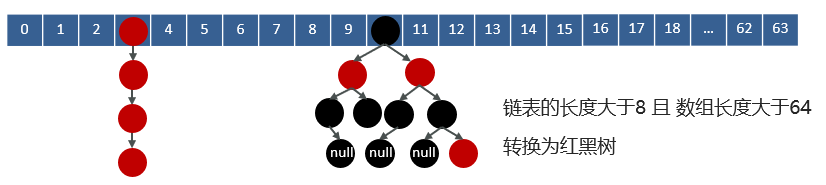\n

## 19. HashMap懒加载、容量与加载因子

**课件第83～86页、在线讲义4.4：** JDK8 HashMap常见默认初始容量16、默认加载因子0.75，数组是懒加载的。

~~~java
static final int DEFAULT_INITIAL_CAPACITY = 1 << 4;
static final float DEFAULT_LOAD_FACTOR = 0.75f;
transient Node<K,V>[] table;
transient int size;
~~~

无参构造通常只保存loadFactor，首次put时resize分配table。threshold一般为容量乘加载因子：初始16时常见阈值12。加载因子越低，桶更稀疏、碰撞可能减少但空间更多；越高则空间紧凑但碰撞、树化和查询成本可能增加。

“初始容量”与“首次分配容量”要区分。构造函数可接受initialCapacity，但实际table仍可能等到首次put才分配，并把容量向上取到合适的2次幂。传入100并不表示底层数组长度恰好100。

扩容触发通常是size超过threshold，不是每次发生碰撞。碰撞多时可能树化或其他桶内处理，但这与全表扩容是不同动作。超大容量、整数溢出和MAXIMUM_CAPACITY会进入边界分支。


## 20. HashMap的put流程：逐步分析

**课件第82～86页、源码讲义第1节：**

1. 计算key的扰动hash。
2. table为空或长度为0时调用resize初始化。
3. 用(n - 1) & hash计算桶下标。
4. 桶为空时新建节点。
5. 桶非空时先检查首节点是否为相同key，相同则准备覆盖。
6. 桶头是TreeNode时走红黑树插入/查找。
7. 普通链表逐节点检查，命中则覆盖，走到尾部则追加新节点。
8. 新增成功后modCount与size递增，超过threshold时扩容。
9. 返回旧value；新增时返回null。
+
+**方法语义补充：** put的返回值是旧值，不是新增后的值。putIfAbsent、compute、merge等方法有不同的null和覆盖语义，不能只背put流程。

课件说“链表长度大于8就树化”需要补充：JDK8源码在插入路径达到树化条件时调用treeifyBin；若table容量小于64，treeifyBin会优先resize，只有容量足够才转换为树。具体binCount存在首节点计数偏移，不能用肉眼的节点数量简单套阈值。

Map更新已有key时通常不增加size，但仍可能影响modCount和迭代器行为需看具体操作。不要在遍历Map时把所有value替换都当作结构性修改，也不要依赖未公开实现细节。


## 21. HashMap寻址算法与2的幂次容量

**课件第91～94页、源码讲义：**

~~~java
static final int hash(Object key) {
    int h;
    return (key == null) ? 0 : (h = key.hashCode()) ^ (h >>> 16);
}
int index = (n - 1) & hash;
~~~

二次扰动把hashCode高16位的信息混入低位，帮助在桶容量较小时使用更多高位信息。它不是加密，也不能修复所有糟糕的hashCode分布。

当n是2的幂时，n-1的二进制低位全为1，位与运算可得到等价于非负取模的桶范围，避免除法。扩容从oldCap到2*oldCap时，用hash & oldCap判断节点留在原下标，或移动到原下标+oldCap，减少重新计算成本。

**边界：** hash是有符号int，位运算结果直接与n-1结合仍能得到合法非负索引，因为n-1只保留低位。自定义实现若用不同容量策略不能直接复制这套公式。

key为null时hash为0，通常进入0号桶。多个hash不同但低位相同仍会碰撞，扰动只改善分布，不消除碰撞。


## 22. HashMap扩容：翻倍、迁移与拆链

**课件第87～89页、源码讲义第2节：** 首次初始化常为16，超过容量乘0.75的阈值后扩容为原来的2倍。

~~~text
old table[j]中的链表
  按 hash & oldCap 分成低位链和高位链
低位链留在j
高位链移动到j + oldCap
~~~

JDK8迁移时保持低位链和高位链的相对顺序，避免JDK7头插法带来的反转。无冲突节点直接按newCap重新计算；树桶调用树的split；普通链表使用loHead/loTail、hiHead/hiTail拆成两条。

一次resize需要遍历旧桶和节点，复杂度按元素数量O(n)，并会产生新数组。连续插入的扩容成本可从整体上均摊，但单次请求仍可能遇到复制延迟。扩容期间新旧数组与节点引用同时存在，内存峰值要纳入容量规划。

阈值翻倍通常与容量翻倍同步，但在自定义初始容量、小容量、最大容量和浮点计算边界下有额外分支。不要将“总是容量16、阈值12”套在所有构造参数和版本。

HashMap扩容不是线程安全迁移。并发写入可能损坏结构或丢更新，即使JDK8避免了某种JDK7环形链表问题，也不能在多线程下直接共享写入。


## 23. JDK7 HashMap并发死循环问题

**课件第95～99页、在线讲义4.7：** JDK7扩容迁移使用头插法，多线程同时迁移同一链表时，指针可能形成环。

~~~text
原链表: A -> B
线程1保存e=A,next=B
线程2头插迁移后: B -> A
线程1继续用旧引用迁移，可能把B.next改为A
结果: A -> B -> A
~~~

这种环会让后续遍历长期循环，表现为CPU占用升高或请求卡住。问题前提是多个线程未经同步修改同一个HashMap，不能把它解释成单线程扩容的普通行为。

JDK8改变桶迁移顺序，通常保持链表相对顺序，避免了课件描述的这一具体死循环路径。但JDK8 HashMap仍然不是线程安全的，可能出现竞态覆盖、可见性问题、结构不一致或数据丢失。

**正确选择：** 只读发布要在安全发布后共享；并发写入使用ConcurrentHashMap或外部锁；需要复合操作时使用compute/putIfAbsent等原子方法并理解其函数执行约束。不要把Collections.synchronizedMap与无锁复合读改写混用。


## 24. HashSet、HashMap与唯一性

**课件第77、80、95页、在线讲义4.8：** HashSet底层通常借助HashMap保存元素，元素作为key，value使用占位对象。

| 类型 | 保存内容 | 重复判断 |
|---|---|---|
| HashMap | key-value | key的hashCode与equals |
| HashSet | 单个元素 | 元素的hashCode与equals |
| LinkedHashMap/Set | 映射/元素 | 同Hash规则，同时维护链接顺序 |
| TreeMap/Set | 排序映射/元素 | 比较器或自然顺序返回0 |

HashSet.add返回是否实际新增。修改Set中元素的参与hashCode字段会造成remove/contains找不到它，和可变HashMap key风险相同。

HashSet使用HashMap并不意味着两者所有行为一致。例如HashMap允许null key，HashSet通常允许一个null元素；迭代顺序仍不保证。实现细节可能因JDK版本调整，接口契约优先。

需要保留插入顺序时用LinkedHashSet；需要排序范围查询时用TreeSet；需要按key映射值时用Map。选择容器时同时考虑顺序、重复、null、并发和内存。


## 25. Hashtable、HashMap与ConcurrentHashMap

**课件第77、95～99页、在线讲义4.9：** 课程表格比较了数据结构、null、hash、扩容和线程安全。

| 维度 | Hashtable | HashMap |
|---|---|---|
| 结构 | 传统数组+链表 | JDK8数组+链表/红黑树 |
| null | key/value通常不允许null | 常见实现允许一个null key和多个null value |
| hash | 直接使用key.hashCode的旧式策略 | 扰动后用位与寻址 |
| 扩容 | 传统策略，常见为旧容量翻倍加一 | 常见翻倍并按低/高位拆分 |
| 并发 | 方法级synchronized | 非线程安全 |
+
+Hashtable的历史实现与具体JDK细节要以源码核对，“扩容翻倍加一”不是现代所有Map的通用规则。它的全方法同步粒度较粗，实际新代码通常评估ConcurrentHashMap。

ConcurrentHashMap允许并发读和更细粒度的更新协作，但不提供HashMap所有null语义，也不保证复合业务逻辑自动原子。size等统计在并发更新期间可能是瞬时近似，按API契约使用。

Collections.synchronizedMap可为单个方法调用加锁，但遍历时需要手动同步：
~~~java
Map<K,V> map = Collections.synchronizedMap(new HashMap<>());
synchronized (map) {
    for (Map.Entry<K,V> e : map.entrySet()) consume(e);
}
~~~

若需要“若不存在则计算并放入”，优先使用ConcurrentHashMap的putIfAbsent/computeIfAbsent等受支持操作，而不是先get再put。计算函数不应产生不可控外部副作用，也要考虑递归更新限制。


## 26. 集合线程安全：容器安全不等于业务安全

集合线程安全至少要分三层：

1. 单次方法调用是否安全。
2. 迭代过程是否安全。
3. 多步业务不变量是否原子。

例如ConcurrentHashMap可以安全地完成某些单键put/get，但“读取余额、计算新值、写回余额”仍需compute、锁、事务或更合适的原子模型。synchronizedList能保护一个add，但检查size后再决定add仍需外部锁或其他原子设计。

局部变量通常只由当前线程拥有，但若对象引用逃逸给其他线程，局部声明本身不能保证安全。安全发布、不可变对象、线程封闭和并发集合要结合使用。

fail-fast迭代器发现并发结构修改后抛异常是调试帮助，不保证一定抛，也不提供数据一致性。CopyOnWriteArrayList适合读多写少且允许写时复制的场景；写多时复制成本很高。

**面试回答：** 先问是并发读、并发写、迭代一致性还是复合操作，再选择同步包装、ConcurrentHashMap、队列、锁、不可变快照或数据库事务。不要只回答“换成线程安全集合”。


## 27. 复杂度与集合选型的综合案例

假设要处理一批订单：

- 需要按输入顺序展示，允许重复，频繁按位置读取。优先ArrayList。
- 需要双端进出，按队列语义处理。优先ArrayDeque或明确的Deque实现。
- 需要根据订单号快速找到订单。用HashMap，订单号作为稳定key。
- 需要按订单号排序或做范围查询。评估TreeMap。
- 需要保存不重复标签且不要求顺序。HashSet。
- 需要插入顺序且去重。LinkedHashSet。
- 多线程更新共享索引。评估ConcurrentHashMap及业务原子操作。

不能仅因HashMap平均查询O(1)就替代所有List，因为List还表达顺序和重复。也不能只因LinkedList有O(1)头插就把它当作所有队列的最佳实现。

容量估算时考虑元素数量、key/value对象、引用、扩容峰值、GC和并发访问。压测应固定JDK、硬件、数据分布、hash冲突、线程数和操作比例，并同时记录吞吐与尾延迟。


## 28. 源码阅读方法：从契约到边界

阅读ArrayList或HashMap源码时按以下顺序：

1. 先看公开接口契约：返回值、异常、null和顺序。
2. 找核心字段：size、capacity、table、threshold、loadFactor、modCount。
3. 追一条主路径：构造、add/put、get、remove、resize。
4. 标出分支：空容器、冲突、树桶、容量边界、异常。
5. 对每个分支写不变量：size与有效元素数量一致，桶索引在范围内，链表/树链接有效。
6. 再分析并发、迭代器、序列化和版本差异。
+
+配套hashmap源码.md的put流程能看到：先resize初始化，再计算(n-1)&hash；桶空时直接放节点；冲突后按首节点、TreeNode或链表分别处理；插入成功后更新size并比较threshold。resize源码再处理容量翻倍、树拆分和低/高位链表迁移。get源码先定位桶，再判断首节点、树或链表。
+
+**源码与接口区分：** HashMap.Node、TREEIFY_THRESHOLD和resize属于实现细节，不能在业务代码中直接依赖。面试可以说明JDK8常见实现，但项目行为应依据当前JDK测试与官方API。


## 29. 高频面试自测

**1. ArrayList底层是什么？** 动态数组，保存元素引用；按索引访问快，扩容需新数组和复制，末尾追加均摊O(1)。

**2. new ArrayList(10)扩容几次？** 仅执行构造语句时没有扩容，指定的是初始容量，不是size。

**3. ArrayList首次add为什么常说容量10？** 针对JDK8无参构造的常见路径。批量添加、显式容量和新JDK实现要分别说明。

**4. ArrayList扩容多少？** JDK8常见新容量约为旧容量1.5倍，但会受minCapacity和最大数组限制影响。

**5. Arrays.asList能add吗？** 不能改变长度；它是固定大小视图，数组槽位和List set共享。

**6. toArray后改List会影响数组吗？** 容器数组通常已复制，不影响数组长度和槽位；元素对象本身仍可能是同一引用。

**7. LinkedList支持下标吗？** 支持List索引API，但按索引查询要遍历，复杂度O(n)。

**8. BST查找一定O(log n)吗？** 只有树高受控时；退化时是O(n)，红黑树通过规则控制高度。

**9. HashMap怎么处理碰撞？** 先定位桶，key相同覆盖value，不同key放链表；JDK8在条件满足时使用红黑树。

**10. 为什么数组长度常是2的幂？** n-1与hash位与可替代取模，扩容时按hash&oldCap快速决定原位或高位。

**11. HashMap阈值怎么算？** 常见threshold约为容量乘0.75，实际还受构造参数、最大容量和版本实现影响。

**12. HashMapput流程？** 初始化，扰动hash，定位桶，空桶新建，相同key覆盖，树桶/链表插入，size递增后必要时resize。

**13. JDK7并发死循环为什么？** 扩容时头插法并发迁移可能反转引用形成环。JDK8调整迁移顺序，但HashMap仍不安全。

**14. HashSet和HashMap区别？** HashSet保存单元素，HashMap保存key-value；HashSet通常以HashMap的key保存元素。

**15. Hashtable和HashMap区别？** 传统同步Map与非同步现代HashMap在结构、null、hash和扩容上不同；具体项目并发通常评估ConcurrentHashMap。

**16. 线程安全集合就能保证业务正确吗？** 不能。复合读改写、迭代、外部事务和业务不变量仍需原子设计。


## 30. 学习练习与验收标准

以下练习只面向隔离学习环境，本轮未执行。

### 练习A：观察ArrayList容量

分别创建无参ArrayList、显式容量10的ArrayList和显式容量0的ArrayList，逐次add并用受支持的调试/反射学习工具记录size与容量变化。

**验收：** 能区分size与capacity，能解释首次分配和1.5倍近似增长，不把私有字段当公开API。

### 练习B：数组与List共享

修改Arrays.asList视图对应数组元素，尝试add/remove，再比较new ArrayList包装和toArray结果。

**验收：** 能说清固定大小、容器浅拷贝、元素引用共享和数组槽位复制的区别。

### 练习C：HashMap碰撞

定义hashCode相同但equals不同的key，观察同桶查询、覆盖和size；再修改参与hashCode的字段。

**验收：** 碰撞不会覆盖不同key，可变key可能无法查找，equals/hashCode契约明确。

### 练习D：扩容迁移

用调试器跟踪容量16扩容到32时hash&oldCap为0和非0的节点。

**验收：** 能解释原下标与原下标+oldCap两种去向，知道树桶有单独split路径。

### 练习E：并发错误

在隔离环境中对HashMap并发put，对比ConcurrentHashMap和外部同步；记录结果而非只看是否抛异常。

**验收：** 能说明HashMap不安全、JDK8没有消除全部竞态、复合操作需要原子方法或锁。

### 练习F：选型压测

固定JDK、数据规模、操作比例和线程数，比较ArrayList、LinkedList、ArrayDeque和HashMap的相关工作负载。

**验收：** 同时报告吞吐、p95/p99、内存和GC，解释理论复杂度与真实常数的差异。


## 31. 版本边界与课件勘误

| 课件/讲义表述 | 笔记中的精确说法 |
|---|---|
| ArrayList初始容量为0 | JDK8无参构造先用空数组标记，首次普通add常分配10；显式容量另算 |
| ArrayList扩容1.5倍 | JDK8常见新容量约旧容量1.5倍，受需求和上限影响 |
| LinkedList不支持下标查询 | 支持索引API，但索引访问需遍历，复杂度O(n) |
| toArray完全和原元素无关 | 容器数组通常复制，元素对象引用仍可能共享 |
| hash不同key必须不同 | 不同key允许hash冲突，靠equals区分 |
| 链表长度大于8就树化 | 还要看table容量，JDK8容量不足时优先resize |
| JDK8扩容算法就是所有新版实现 | 说明JDK8源码路径，实际JDK版本需核对 |
| Hashtable扩容固定翻倍加一 | 作为历史实现常见描述，不能当所有版本/Map通用规则 |
| JDK8解决HashMap线程安全 | 只避免课件所述JDK7环形迁移路径，HashMap仍非线程安全 |
| fail-fast保证并发安全 | 只是尽力检测结构修改，不能替代同步 |
+
+课件PPT有100页，第100页为空白。PPT第90页提到hash-demo.jar及JDK14以上运行命令；本篇仅记录资料存在和课程意图，未运行JAR。PPT、在线正文和MD源码对JDK8路径的叙述一致，但新JDK私有实现可能调整。
+
+面试中可以说“以JDK8 HashMap源码为例”，然后补充阈值和实现细节不是Map接口契约。涉及Java 21等新版本时，重新核对源码和官方API，不要把旧版字段名当作稳定扩展点。


## 32. 来源与覆盖范围

### 课件页码覆盖

| PPT页码 | 主题 | 本笔记 |
|---|---|---|
| 1～4 | 集合框架、数据结构路线 | 导读、1、15～17 |
| 5～15 | 时间/空间复杂度 | 2～4 |
| 16～25 | List、数组与复杂度 | 5、9 |
| 26～39 | ArrayList成员、构造、add、扩容、转换 | 6～11 |
| 40～51 | 链表、双向链表、List比较 | 12～14 |
| 52～64 | 二叉树、BST、红黑树 | 15～16 |
| 65～76 | 散列表、冲突、拉链法 | 17 |
| 77～81 | HashMap原理与JDK7/JDK8 | 18、24～25 |
| 82～90 | put、属性、扩容和动画资料 | 19～22、28 |
| 91～94 | 寻址算法和2次幂容量 | 21 |
| 95～99 | JDK7并发死循环、面试问答 | 23、25～29 |
| 100 | 空白 | 无需补写 |

在线正文还覆盖HashSet、Hashtable、ConcurrentHashMap选型及List/HashMap面试模拟，已纳入24～29。配套MD源码的put、resize、get流程已纳入18～22。

### 来源

- 网盘分享：[2023版Java面试教程](https://pan.baidu.com/s/1NQZDW-9_VCnEUXcXp_G-bA?pwd=9987)，提取码9987。
- 主课件：07-常见集合篇/PPT/07-常见集合篇.pptx，100页。
- 在线讲义入口：[面试专题](https://heuqqdmbyk.feishu.cn/wiki/RymLwLLWfieibHkjf17cKhY4nlf)。
- 实际正文：[常见集合篇](https://heuqqdmbyk.feishu.cn/wiki/Pbm0w1CgFi1Px4klDNdcP57inJc)。

本篇仅生成学习笔记。视频未观看或转写，hash-demo.jar未运行，源码MD未取得本地下载，所有示例未编译执行，未进行并发压测。00～06已有笔记保持原内容。
